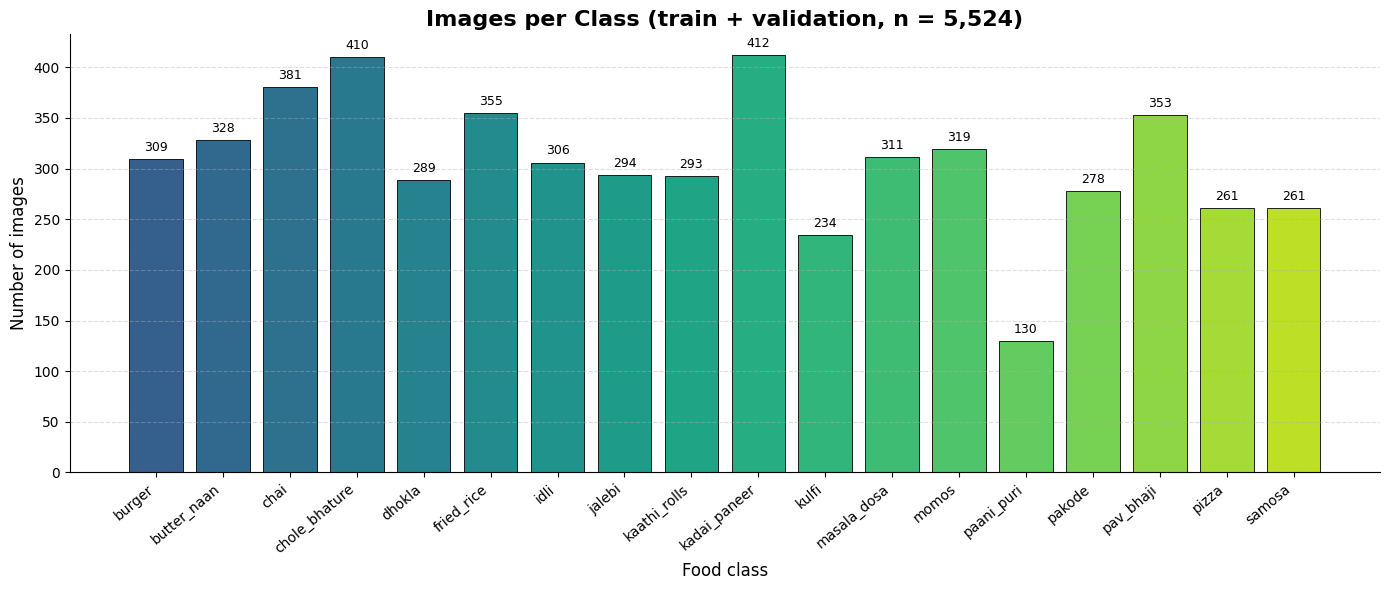

Classes: 18, total images: 5,524 (min 130, max 412)


In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np

# Images per class in the train/val split used for training and evaluation
# (data/processed/, created by src/train.py). Dotfiles such as .DS_Store are ignored.
splits = ["data/processed/train", "data/processed/val"]

def count_images(folder):
    return len([f for f in os.listdir(folder) if not f.startswith(".")])

classes = sorted(c for c in os.listdir(splits[0])
                 if not c.startswith(".") and os.path.isdir(os.path.join(splits[0], c)))
counts = [sum(count_images(os.path.join(s, c)) for s in splits) for c in classes]
total = sum(counts)

colors = plt.cm.viridis(np.linspace(0.3, 0.9, len(classes)))

plt.figure(figsize=(14, 6))
bars = plt.bar(classes, counts, color=colors, edgecolor="black", linewidth=0.6)

plt.title(f"Images per Class (train + validation, n = {total:,})", fontsize=16, fontweight="bold")
plt.ylabel("Number of images", fontsize=12)
plt.xlabel("Food class", fontsize=12)
plt.xticks(rotation=40, ha="right", fontsize=10)
plt.yticks(fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.4)
for spine in ["top", "right"]:
    plt.gca().spines[spine].set_visible(False)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + 5, f"{height}",
             ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.savefig("distribution_chart.png", dpi=300)
plt.show()
print(f"Classes: {len(classes)}, total images: {total:,} (min {min(counts)}, max {max(counts)})")

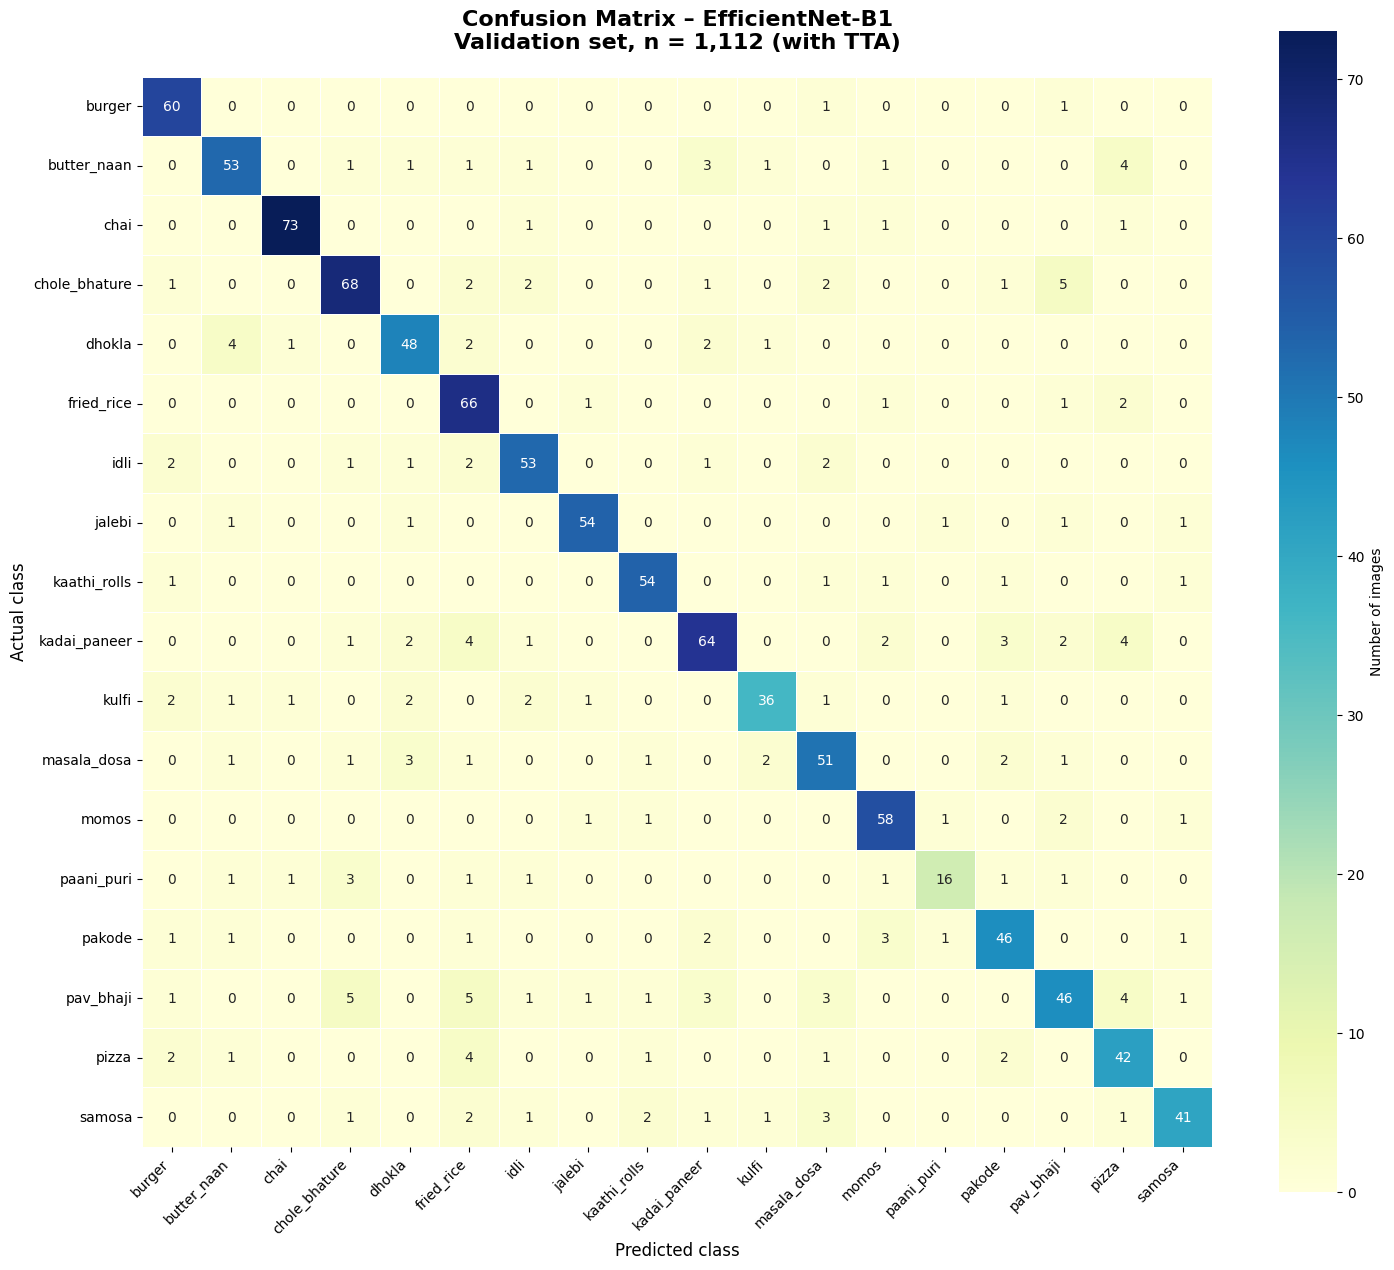

Classes: 18, total images in matrix: 1,112


In [2]:
import json
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Confusion matrix saved by src/evaluate_model.py
# (validation set, predictions made with test-time augmentation)
with open("evaluation_results.json") as f:
    results = json.load(f)

classes = results["class_names"]          # 18 classes, in the model's label order
cm = np.array(results["confusion_matrix"])
n = int(cm.sum())
assert cm.shape == (len(classes), len(classes))
assert n == results["num_samples"]

plt.figure(figsize=(15, 13))
ax = sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    square=True,
    linewidths=0.5,
    linecolor="white",
    xticklabels=classes,
    yticklabels=classes,
    cbar_kws={"label": "Number of images"},
)

ax.set_title(f"Confusion Matrix – EfficientNet-B1\nValidation set, n = {n:,} (with TTA)",
             fontsize=16, pad=20, fontweight="bold")
ax.set_xlabel("Predicted class", fontsize=12)
ax.set_ylabel("Actual class", fontsize=12)
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.yticks(rotation=0, fontsize=10)

plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()
print(f"Classes: {len(classes)}, total images in matrix: {n:,}")

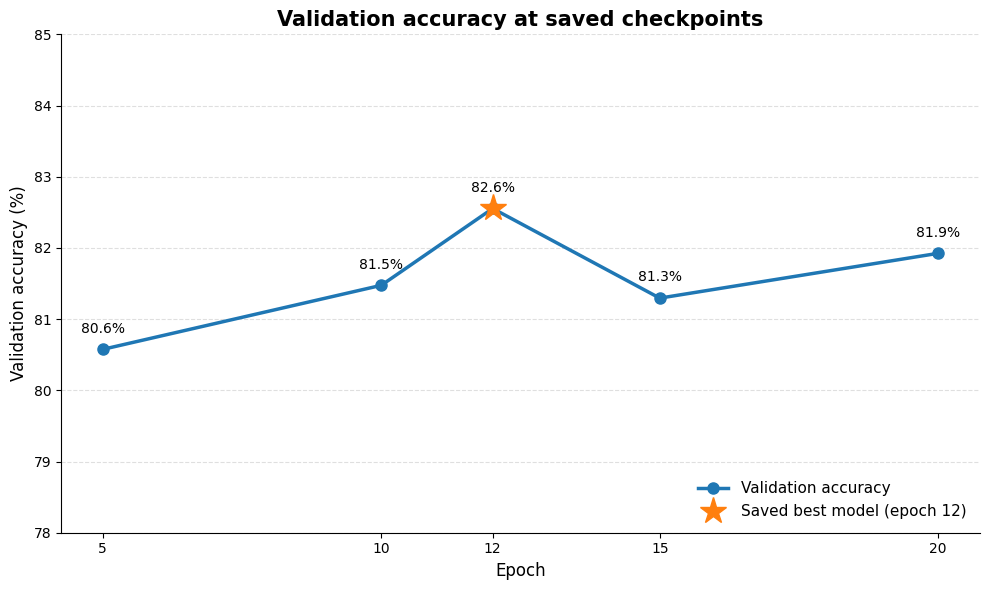

epoch  5: 80.58%
epoch 10: 81.47%
epoch 12: 82.55%  <- saved best model
epoch 15: 81.29%
epoch 20: 81.92%


In [3]:
import json
import matplotlib.pyplot as plt

# Validation accuracy stored inside the saved checkpoints.
# Training saved a checkpoint every 5 epochs plus the best model; no per-epoch
# history was logged, so these are the only real data points available.
# The values are exported from the (untracked) .pth files by
#   python scripts/export_checkpoint_metrics.py
with open("results/checkpoint_val_accuracy.json") as f:
    checkpoints = json.load(f)["checkpoints"]

points = sorted((c["epoch"], c["val_accuracy"], c["saved_best_model"]) for c in checkpoints)

epochs = [e for e, _, _ in points]
accs = [a for _, a, _ in points]
best_epoch, best_acc, _ = next(pt for pt in points if pt[2])

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(epochs, accs, color="#1f77b4", linewidth=2.5, marker="o", markersize=8,
        label="Validation accuracy")
ax.plot([best_epoch], [best_acc], marker="*", markersize=20, color="#ff7f0e",
        linestyle="none", label=f"Saved best model (epoch {best_epoch})")

for e, a in zip(epochs, accs):
    ax.annotate(f"{a:.1f}%", (e, a), textcoords="offset points", xytext=(0, 12),
                ha="center", fontsize=10)

ax.set_title("Validation accuracy at saved checkpoints", fontsize=15, fontweight="bold")
ax.set_xlabel("Epoch", fontsize=12)
ax.set_ylabel("Validation accuracy (%)", fontsize=12)
ax.set_xticks(epochs)
ax.set_ylim(78, 85)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend(frameon=False, fontsize=11, loc="lower right")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.savefig("training_curves.png", dpi=300)
plt.show()
for e, a, best in points:
    print(f"epoch {e:>2}: {a:.2f}%{'  <- saved best model' if best else ''}")